# TP2 — Prédiction des prix immobiliers
## 02 — Modélisation et comparaison des modèles

### Objectif
Entraîner et comparer plusieurs modèles de régression
sur le dataset California Housing.

### Modèles candidats
- ExtraTrees Regressor
- HistGradientBoosting Regressor
- XGBoost Regressor
- LightGBM Regressor
- CatBoost Regressor

### Métriques
- MAE
- RMSE
- R²

### Protocole
- Train : 70 %
- Validation : 15 %
- Test : 15 % (réservé à l'évaluation finale)

In [1]:
import pandas as pd
from pathlib import Path

# Identifier le dossier du projet
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Chemin des partitions
splits_dir = project_dir / "data" / "splits"

# Recharger les données
train_df = pd.read_csv(splits_dir / "train.csv")
val_df = pd.read_csv(splits_dir / "validation.csv")

# Vérifier les dimensions
print("Train :", train_df.shape)
print("Validation :", val_df.shape)

# Aperçu
display(train_df.head())

Train : (14448, 9)
Validation : (3096, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,4.8750,15.0,6.720833,1.262500,702.0,2.925000,32.91,-117.15,1.693
1,3.2371,33.0,4.289700,1.008584,2170.0,4.656652,33.92,-118.05,1.547
2,1.9038,35.0,4.155080,1.018717,1487.0,3.975936,34.08,-118.19,1.395
3,8.5282,25.0,7.831050,1.107306,1284.0,2.931507,34.15,-117.66,3.601
4,3.7833,47.0,5.438356,1.058219,827.0,2.832192,33.99,-118.06,1.661


In [2]:
# Variable à prédire
target = "MedHouseVal"

# Entraînement
X_train = train_df.drop(columns=[target])
y_train = train_df[target]

# Validation
X_val = val_df.drop(columns=[target])
y_val = val_df[target]

# Vérifications
print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("X_val :", X_val.shape)
print("y_val :", y_val.shape)

print("\nVariables utilisées :")
print(X_train.columns.tolist())

X_train : (14448, 8)
y_train : (14448,)
X_val : (3096, 8)
y_val : (3096,)

Variables utilisées :
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [3]:
from sklearn.dummy import DummyRegressor

# 1. Créer notre modèle baseline
baseline = DummyRegressor(strategy="mean")

# 2. Entraîner le modèle
baseline.fit(X_train, y_train)

# 3. Effectuer des prédictions sur la validation
y_pred_baseline = baseline.predict(X_val)

# 4. Examiner les prédictions
print("Moyenne apprise :", baseline.constant_[0, 0])

print("\nPremières prédictions :")
print(y_pred_baseline[:5])

print("\nPremières valeurs réelles :")
print(y_val.iloc[:5].values)

Moyenne apprise : 2.0629636537929126

Premières prédictions :
[2.06296365 2.06296365 2.06296365 2.06296365 2.06296365]

Premières valeurs réelles :
[1.554 0.933 2.291 3.167 1.125]


In [4]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_val, y_pred_baseline)
rmse = root_mean_squared_error(y_val, y_pred_baseline)
r2 = r2_score(y_val, y_pred_baseline)

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

print(f"\nMAE en dollars : {mae * 100000:,.2f} $")

MAE  : 0.9078
RMSE : 1.1572
R²   : -0.0007

MAE en dollars : 90,775.13 $


In [5]:
# Tableau qui contiendra les résultats des expériences
resultats_modeles = []

# Enregistrer les résultats du DummyRegressor
resultats_modeles.append({
    "Modele": "DummyRegressor",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
})

# Afficher le tableau
display(pd.DataFrame(resultats_modeles))

,Modele,MAE,RMSE,R2
0,DummyRegressor,0.907751,1.157226,-0.000713


In [6]:
from sklearn.ensemble import ExtraTreesRegressor
from time import perf_counter

# 1. Création du modèle
extra_trees = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

# 2. Entraînement
debut = perf_counter()

extra_trees.fit(X_train, y_train)

temps_entrainement = perf_counter() - debut

# 3. Prédictions sur la validation
y_pred_extra = extra_trees.predict(X_val)

print(f"Temps d'entraînement : {temps_entrainement:.2f} secondes")

print("\nPremières prédictions :")
print(y_pred_extra[:5])

print("\nValeurs réelles :")
print(y_val.iloc[:5].values)

Temps d'entraînement : 1.46 secondes

Premières prédictions :
[1.65402    1.316275   2.38777    2.87313505 1.234985  ]

Valeurs réelles :
[1.554 0.933 2.291 3.167 1.125]


In [7]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

# Évaluation sur validation
mae_extra = mean_absolute_error(y_val, y_pred_extra)
rmse_extra = root_mean_squared_error(y_val, y_pred_extra)
r2_extra = r2_score(y_val, y_pred_extra)

print("Résultats ExtraTrees :")
print(f"MAE  : {mae_extra:.4f}")
print(f"RMSE : {rmse_extra:.4f}")
print(f"R²   : {r2_extra:.4f}")

print(f"\nMAE en dollars : {mae_extra * 100000:,.2f} $")

Résultats ExtraTrees :
MAE  : 0.3314
RMSE : 0.5042
R²   : 0.8100

MAE en dollars : 33,137.37 $


In [8]:
# 1. Prédictions sur les données d'entraînement
y_pred_train = extra_trees.predict(X_train)

# 2. Calculer les métriques sur Train
mae_train = mean_absolute_error(y_train, y_pred_train)
rmse_train = root_mean_squared_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

# 3. Comparer Train et Validation
comparaison_extra = pd.DataFrame({
    "Métrique": ["MAE", "RMSE", "R²"],
    "Train": [mae_train, rmse_train, r2_train],
    "Validation": [mae_extra, rmse_extra, r2_extra]
})

display(comparaison_extra.round(4))

,Métrique,Train,Validation
0,MAE,0.0,0.3314
1,RMSE,0.0,0.5042
2,R²,1.0,0.8100


In [9]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

resultats_experience = []

for leaf in [1, 2, 5, 10]:

    modele = ExtraTreesRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=leaf,
        random_state=42,
        n_jobs=-1
    )

    # Entraînement
    modele.fit(X_train, y_train)

    # Prédictions
    pred_train = modele.predict(X_train)
    pred_val = modele.predict(X_val)

    # Enregistrer les performances
    resultats_experience.append({
        "min_samples_leaf": leaf,
        "MAE_train": mean_absolute_error(y_train, pred_train),
        "MAE_val": mean_absolute_error(y_val, pred_val),
        "R2_train": r2_score(y_train, pred_train),
        "R2_val": r2_score(y_val, pred_val)
    })

comparaison_hyperparametres = pd.DataFrame(
    resultats_experience
)

display(comparaison_hyperparametres.round(4))

,min_samples_leaf,MAE_train,MAE_val,R2_train,R2_val
0,1,0.0000,0.3314,1.0000,0.8100
1,2,0.1045,0.3336,0.9767,0.8059
2,5,0.2614,0.3552,0.8822,0.7885
3,10,0.3333,0.3805,0.8182,0.7667


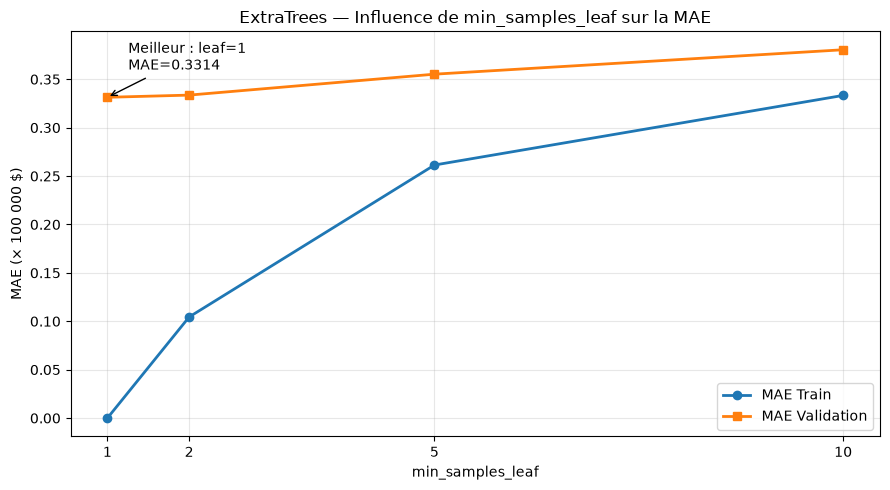

In [10]:
import matplotlib.pyplot as plt
from pathlib import Path

# Résultats de l'expérience précédente
df_plot = comparaison_hyperparametres.sort_values("min_samples_leaf")

# Création du graphique
plt.figure(figsize=(9, 5))

plt.plot(
    df_plot["min_samples_leaf"],
    df_plot["MAE_train"],
    marker="o",
    linewidth=2,
    label="MAE Train"
)

plt.plot(
    df_plot["min_samples_leaf"],
    df_plot["MAE_val"],
    marker="s",
    linewidth=2,
    label="MAE Validation"
)

# Mise en forme
plt.title("ExtraTrees — Influence de min_samples_leaf sur la MAE")
plt.xlabel("min_samples_leaf")
plt.ylabel("MAE (× 100 000 $)")
plt.xticks(df_plot["min_samples_leaf"])
plt.legend()
plt.grid(alpha=0.3)

# Identifier la meilleure configuration sur validation
best_idx = df_plot["MAE_val"].idxmin()
best_leaf = df_plot.loc[best_idx, "min_samples_leaf"]
best_mae = df_plot.loc[best_idx, "MAE_val"]

plt.annotate(
    f"Meilleur : leaf={best_leaf}\nMAE={best_mae:.4f}",
    xy=(best_leaf, best_mae),
    xytext=(15, 20),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->")
)

plt.tight_layout()

# Sauvegarde du graphique
project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    reports_dir / "extratrees_min_samples_leaf_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
df_plot.to_csv(
    reports_dir / "extratrees_min_samples_leaf_results.csv",
    index=False
)

In [12]:
profondeurs = [10, 15, 20, 30, None]

resultats_depth = []

for depth in profondeurs:

    modele = ExtraTreesRegressor(
        n_estimators=200,
        max_depth=depth,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    )

    # Entraînement
    modele.fit(X_train, y_train)

    # Prédictions
    pred_train = modele.predict(X_train)
    pred_val = modele.predict(X_val)

    # Évaluation
    resultats_depth.append({
        "max_depth": str(depth),
        "MAE_train": mean_absolute_error(y_train, pred_train),
        "MAE_val": mean_absolute_error(y_val, pred_val),
        "R2_train": r2_score(y_train, pred_train),
        "R2_val": r2_score(y_val, pred_val)
    })

comparaison_depth = pd.DataFrame(resultats_depth)

display(comparaison_depth.round(4))

,max_depth,MAE_train,MAE_val,R2_train,R2_val
0,10,0.4234,0.4524,0.7382,0.7004
1,15,0.2319,0.3650,0.9160,0.7851
2,20,0.0791,0.3388,0.9886,0.8051
3,30,0.0016,0.3314,1.0000,0.8094
4,None,0.0000,0.3314,1.0000,0.8100


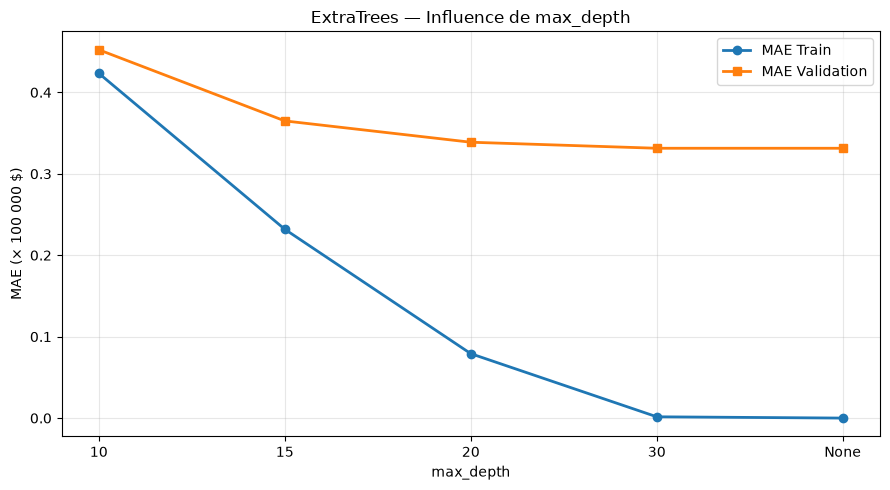

Résultats et graphique sauvegardés.


In [13]:
import matplotlib.pyplot as plt
from pathlib import Path

# Résultats de l'expérience
df_plot = comparaison_depth.copy()

# Positions pour représenter également None
positions = range(len(df_plot))
labels = df_plot["max_depth"].astype(str)

plt.figure(figsize=(9, 5))

plt.plot(
    positions,
    df_plot["MAE_train"],
    marker="o",
    linewidth=2,
    label="MAE Train"
)

plt.plot(
    positions,
    df_plot["MAE_val"],
    marker="s",
    linewidth=2,
    label="MAE Validation"
)

plt.xticks(positions, labels)
plt.xlabel("max_depth")
plt.ylabel("MAE (× 100 000 $)")
plt.title("ExtraTrees — Influence de max_depth")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Dossier du projet
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

# Sauvegarder le graphique
plt.savefig(
    reports_dir / "extratrees_max_depth_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Sauvegarder les résultats numériques
df_plot.to_csv(
    reports_dir / "extratrees_max_depth_results.csv",
    index=False
)

print("Résultats et graphique sauvegardés.")

In [14]:
from sklearn.ensemble import HistGradientBoostingRegressor
from time import perf_counter

# 1. Création du modèle
hist_gbm = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    early_stopping=False,
    random_state=42
)

# 2. Mesurer le temps d'entraînement
debut = perf_counter()

# 3. Entraîner le modèle
hist_gbm.fit(X_train, y_train)

temps_histgbm = perf_counter() - debut

# 4. Effectuer les prédictions
y_pred_hist_train = hist_gbm.predict(X_train)
y_pred_hist_val = hist_gbm.predict(X_val)

# 5. Afficher les premières prédictions
print(f"Temps d'entraînement : {temps_histgbm:.2f} secondes")
print(f"Nombre d'itérations : {hist_gbm.n_iter_}")

print("\nPremières prédictions :")
print(y_pred_hist_val[:5])

print("\nValeurs réelles :")
print(y_val.iloc[:5].values)

Temps d'entraînement : 0.48 secondes
Nombre d'itérations : 200

Premières prédictions :
[1.64990129 1.19922629 2.3719436  3.24385011 1.16829636]

Valeurs réelles :
[1.554 0.933 2.291 3.167 1.125]


In [15]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

# Métriques Train
mae_hist_train = mean_absolute_error(
    y_train, y_pred_hist_train
)

rmse_hist_train = root_mean_squared_error(
    y_train, y_pred_hist_train
)

r2_hist_train = r2_score(
    y_train, y_pred_hist_train
)

# Métriques Validation
mae_hist_val = mean_absolute_error(
    y_val, y_pred_hist_val
)

rmse_hist_val = root_mean_squared_error(
    y_val, y_pred_hist_val
)

r2_hist_val = r2_score(
    y_val, y_pred_hist_val
)

# Tableau Train vs Validation
comparaison_histgbm = pd.DataFrame({
    "Métrique": ["MAE", "RMSE", "R²"],
    "Train": [
        mae_hist_train,
        rmse_hist_train,
        r2_hist_train
    ],
    "Validation": [
        mae_hist_val,
        rmse_hist_val,
        r2_hist_val
    ]
})

display(comparaison_histgbm.round(4))

print(f"\nMAE Validation : {mae_hist_val * 100000:,.2f} $")

,Métrique,Train,Validation
0,MAE,0.2293,0.3024
1,RMSE,0.3318,0.4616
2,R²,0.9175,0.8408



MAE Validation : 30,241.55 $


In [17]:
# Reconstruire le tableau avec les 3 modèles
# à partir des métriques déjà calculées

resultats_modeles = [
    {
        "Modele": "DummyRegressor",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    },
    {
        "Modele": "ExtraTrees",
        "MAE": mae_extra,
        "RMSE": rmse_extra,
        "R2": r2_extra
    },
    {
        "Modele": "HistGBM",
        "MAE": mae_hist_val,
        "RMSE": rmse_hist_val,
        "R2": r2_hist_val
    }
]

comparaison = pd.DataFrame(resultats_modeles)

# Classer les modèles selon leur MAE
comparaison = comparaison.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

display(comparaison.round(4))

,Modele,MAE,RMSE,R2
0,HistGBM,0.3024,0.4616,0.8408
1,ExtraTrees,0.3314,0.5042,0.8100
2,DummyRegressor,0.9078,1.1572,-0.0007


In [18]:
from pathlib import Path

project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

comparaison.to_csv(
    reports_dir / "comparaison_modeles_initiale.csv",
    index=False
)

print("Comparaison sauvegardée avec les 3 modèles.")

Comparaison sauvegardée avec les 3 modèles.


In [19]:
from xgboost import XGBRegressor
from time import perf_counter

# 1. Création du modèle
xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    subsample=1.0,
    colsample_bytree=1.0,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# 2. Entraînement
debut = perf_counter()

xgb_model.fit(X_train, y_train)

temps_xgb = perf_counter() - debut

# 3. Prédictions
y_pred_xgb_train = xgb_model.predict(X_train)
y_pred_xgb_val = xgb_model.predict(X_val)

print(f"Temps d'entraînement : {temps_xgb:.2f} secondes")

print("\nPremières prédictions :")
print(y_pred_xgb_val[:5])

print("\nValeurs réelles :")
print(y_val.iloc[:5].values)

Temps d'entraînement : 0.73 secondes

Premières prédictions :
[1.7264588 1.4142121 2.5578718 2.9811099 1.153612 ]

Valeurs réelles :
[1.554 0.933 2.291 3.167 1.125]


In [20]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

# Évaluation sur Train
mae_xgb_train = mean_absolute_error(
    y_train, y_pred_xgb_train
)

rmse_xgb_train = root_mean_squared_error(
    y_train, y_pred_xgb_train
)

r2_xgb_train = r2_score(
    y_train, y_pred_xgb_train
)

# Évaluation sur Validation
mae_xgb_val = mean_absolute_error(
    y_val, y_pred_xgb_val
)

rmse_xgb_val = root_mean_squared_error(
    y_val, y_pred_xgb_val
)

r2_xgb_val = r2_score(
    y_val, y_pred_xgb_val
)

# Tableau de comparaison
comparaison_xgb = pd.DataFrame({
    "Métrique": ["MAE", "RMSE", "R²"],
    "Train": [
        mae_xgb_train,
        rmse_xgb_train,
        r2_xgb_train
    ],
    "Validation": [
        mae_xgb_val,
        rmse_xgb_val,
        r2_xgb_val
    ]
})

display(comparaison_xgb.round(4))

print(f"\nMAE Validation : {mae_xgb_val * 100000:,.2f} $")

,Métrique,Train,Validation
0,MAE,0.2044,0.3088
1,RMSE,0.2919,0.4741
2,R²,0.9361,0.8320



MAE Validation : 30,881.35 $


In [21]:
from pathlib import Path
import pandas as pd

# Éviter les doublons lors d'une réexécution
resultats_modeles = [
    r for r in resultats_modeles
    if r["Modele"] != "XGBoost"
]

# Ajouter les résultats de XGBoost
resultats_modeles.append({
    "Modele": "XGBoost",
    "MAE": mae_xgb_val,
    "RMSE": rmse_xgb_val,
    "R2": r2_xgb_val
})

# Construire le tableau comparatif
comparaison = pd.DataFrame(resultats_modeles)
comparaison = comparaison.sort_values("MAE").reset_index(drop=True)

display(comparaison.round(4))

# Sauvegarder les résultats
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

comparaison.to_csv(
    reports_dir / "comparaison_modeles_initiale.csv",
    index=False
)

print("Résultats sauvegardés.")

,Modele,MAE,RMSE,R2
0,HistGBM,0.3024,0.4616,0.8408
1,XGBoost,0.3088,0.4741,0.8320
2,ExtraTrees,0.3314,0.5042,0.8100
3,DummyRegressor,0.9078,1.1572,-0.0007


Résultats sauvegardés.


In [22]:
from lightgbm import LGBMRegressor
from time import perf_counter

# Création du modèle
lgbm_model = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.1,
    num_leaves=31,
    min_child_samples=20,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Entraînement
debut = perf_counter()

lgbm_model.fit(X_train, y_train)

temps_lgbm = perf_counter() - debut

# Prédictions
y_pred_lgbm_train = lgbm_model.predict(X_train)
y_pred_lgbm_val = lgbm_model.predict(X_val)

print(f"Temps d'entraînement : {temps_lgbm:.2f} secondes")

print("\nPremières prédictions :")
print(y_pred_lgbm_val[:5])

print("\nValeurs réelles :")
print(y_val.iloc[:5].values)

Temps d'entraînement : 0.24 secondes

Premières prédictions :
[1.72480514 1.10108534 2.38049677 3.0388607  1.19920644]

Valeurs réelles :
[1.554 0.933 2.291 3.167 1.125]


In [23]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

# Train
mae_lgbm_train = mean_absolute_error(y_train, y_pred_lgbm_train)
rmse_lgbm_train = root_mean_squared_error(y_train, y_pred_lgbm_train)
r2_lgbm_train = r2_score(y_train, y_pred_lgbm_train)

# Validation
mae_lgbm_val = mean_absolute_error(y_val, y_pred_lgbm_val)
rmse_lgbm_val = root_mean_squared_error(y_val, y_pred_lgbm_val)
r2_lgbm_val = r2_score(y_val, y_pred_lgbm_val)

# Tableau comparatif
comparaison_lgbm = pd.DataFrame({
    "Métrique": ["MAE", "RMSE", "R²"],
    "Train": [mae_lgbm_train, rmse_lgbm_train, r2_lgbm_train],
    "Validation": [mae_lgbm_val, rmse_lgbm_val, r2_lgbm_val]
})

display(comparaison_lgbm.round(4))

print(f"\nMAE Validation : {mae_lgbm_val * 100000:,.2f} $")

,Métrique,Train,Validation
0,MAE,0.2298,0.3022
1,RMSE,0.3322,0.4623
2,R²,0.9173,0.8403



MAE Validation : 30,216.40 $


In [24]:
# Éviter les doublons
resultats_modeles = [
    r for r in resultats_modeles
    if r["Modele"] != "LightGBM"
]

# Ajouter les métriques LightGBM
resultats_modeles.append({
    "Modele": "LightGBM",
    "MAE": mae_lgbm_val,
    "RMSE": rmse_lgbm_val,
    "R2": r2_lgbm_val
})

# Construire le tableau comparatif
comparaison = pd.DataFrame(resultats_modeles)

comparaison = (
    comparaison
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(comparaison.round(4))

# Sauvegarder les résultats
from pathlib import Path

project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

comparaison.to_csv(
    reports_dir / "comparaison_modeles_initiale.csv",
    index=False
)

print("LightGBM ajouté à la comparaison.")

,Modele,MAE,RMSE,R2
0,LightGBM,0.3022,0.4623,0.8403
1,HistGBM,0.3024,0.4616,0.8408
2,XGBoost,0.3088,0.4741,0.8320
3,ExtraTrees,0.3314,0.5042,0.8100
4,DummyRegressor,0.9078,1.1572,-0.0007


LightGBM ajouté à la comparaison.


In [25]:
from catboost import CatBoostRegressor
from time import perf_counter

# 1. Créer le modèle
cat_model = CatBoostRegressor(
    iterations=200,
    learning_rate=0.1,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1
)

# 2. Entraîner le modèle
debut = perf_counter()

cat_model.fit(X_train, y_train)

temps_cat = perf_counter() - debut

# 3. Effectuer les prédictions
y_pred_cat_train = cat_model.predict(X_train)
y_pred_cat_val = cat_model.predict(X_val)

# 4. Afficher les résultats
print(f"Temps d'entraînement : {temps_cat:.2f} secondes")

print("\nPremières prédictions :")
print(y_pred_cat_val[:5])

print("\nValeurs réelles :")
print(y_val.iloc[:5].values)

Temps d'entraînement : 0.76 secondes

Premières prédictions :
[1.49902662 1.34304018 2.47331765 3.37863445 1.2466968 ]

Valeurs réelles :
[1.554 0.933 2.291 3.167 1.125]


In [26]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

# Évaluation Train
mae_cat_train = mean_absolute_error(
    y_train, y_pred_cat_train
)

rmse_cat_train = root_mean_squared_error(
    y_train, y_pred_cat_train
)

r2_cat_train = r2_score(
    y_train, y_pred_cat_train
)

# Évaluation Validation
mae_cat_val = mean_absolute_error(
    y_val, y_pred_cat_val
)

rmse_cat_val = root_mean_squared_error(
    y_val, y_pred_cat_val
)

r2_cat_val = r2_score(
    y_val, y_pred_cat_val
)

# Tableau Train vs Validation
comparaison_cat = pd.DataFrame({
    "Métrique": ["MAE", "RMSE", "R²"],
    "Train": [
        mae_cat_train,
        rmse_cat_train,
        r2_cat_train
    ],
    "Validation": [
        mae_cat_val,
        rmse_cat_val,
        r2_cat_val
    ]
})

display(comparaison_cat.round(4))

print(f"\nMAE Validation : {mae_cat_val * 100000:,.2f} $")

,Métrique,Train,Validation
0,MAE,0.2985,0.3229
1,RMSE,0.4316,0.4806
2,R²,0.8604,0.8274



MAE Validation : 32,292.98 $


In [27]:
import pandas as pd
from pathlib import Path

# Résultats de tous les modèles
resultats_modeles = [
    {
        "Modele": "DummyRegressor",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    },
    {
        "Modele": "ExtraTrees",
        "MAE": mae_extra,
        "RMSE": rmse_extra,
        "R2": r2_extra
    },
    {
        "Modele": "HistGBM",
        "MAE": mae_hist_val,
        "RMSE": rmse_hist_val,
        "R2": r2_hist_val
    },
    {
        "Modele": "XGBoost",
        "MAE": mae_xgb_val,
        "RMSE": rmse_xgb_val,
        "R2": r2_xgb_val
    },
    {
        "Modele": "LightGBM",
        "MAE": mae_lgbm_val,
        "RMSE": rmse_lgbm_val,
        "R2": r2_lgbm_val
    },
    {
        "Modele": "CatBoost",
        "MAE": mae_cat_val,
        "RMSE": rmse_cat_val,
        "R2": r2_cat_val
    }
]

# Création du DataFrame comparatif
comparaison = pd.DataFrame(resultats_modeles)

# Classement du meilleur au moins performant
comparaison = comparaison.sort_values(
    "MAE",
    ascending=True
).reset_index(drop=True)

display(comparaison.round(4))

# Sauvegarde
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

comparaison.to_csv(
    reports_dir / "comparaison_modeles_initiale.csv",
    index=False
)

print("Comparaison initiale sauvegardée.")

,Modele,MAE,RMSE,R2
0,LightGBM,0.3022,0.4623,0.8403
1,HistGBM,0.3024,0.4616,0.8408
2,XGBoost,0.3088,0.4741,0.8320
3,CatBoost,0.3229,0.4806,0.8274
4,ExtraTrees,0.3314,0.5042,0.8100
5,DummyRegressor,0.9078,1.1572,-0.0007


Comparaison initiale sauvegardée.
